Cancer is not one disease but hundreds, united by one feature: cells that keep dividing when they shouldn't, invade where they don't belong, and eventually disrupt the body. Every chapter so far has prepared for this one. Cancer is a disease of DNA (P3) whose mutations change proteins (P4, P5) that regulate genes (P6), control the cell cycle and death (P7), pass growth signals (P9) and hide tumours from immunity (P10). And it develops by mutation and selection among the body's own cells, which is evolution (P8).

:::eli5
Your body is a well-run society of cells. Each cell divides only when told to, stays in its place, and kills itself if it becomes damaged. Cancer starts when one cell picks up a series of typos in its instruction book: one typo jams the accelerator, another cuts the brakes, another disables the self-destruct button. Each typo gives that cell's family a small advantage, so the family grows, and the bigger it gets, the more likely one member picks up the next typo. After enough typos the family ignores all the rules. That family is a tumour.
:::

## What makes a tumour

A **tumour** (or neoplasm) is an abnormal mass of cells. It is **benign** if it stays in place (most moles, fibroids) and **malignant**, a cancer, if it invades surrounding tissue and can spread through blood or lymph to form **metastases** in other organs. Metastasis causes most cancer deaths.

Cancers are named by the cell type they arise from:

| Type | Origin | Examples |
|---|---|---|
| **Carcinoma** | epithelial cells (linings and glands); about 85% of cancers | breast, lung, colorectal, prostate, pancreatic |
| **Sarcoma** | connective tissue | bone, muscle, fat |
| **Leukaemia, lymphoma, myeloma** | blood and immune cells | CML, AML, Hodgkin lymphoma |
| **Glioma** | glial cells of the brain | glioblastoma |
| **Melanoma** | pigment cells | skin melanoma |

## Oncogenes and tumour suppressors

Cancer genes come in two kinds, and the car analogy is standard:

- **Oncogenes** are accelerators stuck down. The normal version (a **proto-oncogene**) promotes growth when told to; a mutation makes it active all the time. One mutated copy is enough (dominant). Examples: *KRAS*, *BRAF*, *EGFR*, *PIK3CA*, *MYC*.
- **Tumour suppressors** are brakes. They stop division or trigger repair and death. Both copies must be lost (recessive at the cell level). Examples: *TP53*, *RB1*, *APC*, *PTEN*, *BRCA1/2*.

Alfred Knudson explained the "two hits" needed for tumour suppressors in 1971 by studying **retinoblastoma**, an eye cancer of children. Children who inherit one broken *RB1* copy in every cell need only one more hit in any retinal cell, so they often get tumours in both eyes, early. In sporadic cases, one cell must lose both copies by chance, so tumours are single and later.

### The two patterns in real tumours

The two kinds of gene leave different fingerprints. An oncogene must be *activated*, and only specific changes do that, so its mutations pile up at a few **hotspot** positions. A tumour suppressor only has to be *broken*, and almost any damaging change works, so its mutations are spread out and often truncate the protein (nonsense mutations and frameshifts, chapter P4).

Let's see this in real data. We downloaded every mutation in eight well-known cancer genes from eight cancer types in **The Cancer Genome Atlas** (TCGA, about 4,200 tumours) through the cBioPortal web service.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import json

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

muts = pd.read_csv("datasets/tcga_driver_mutations.csv")
n_samples = json.load(open("datasets/tcga_sample_counts.json"))
names = {"coadread": "colorectal", "brca": "breast", "luad": "lung adeno.", "paad": "pancreatic", "skcm": "melanoma",
         "gbm": "glioblastoma", "ucec": "endometrial", "lgg": "lower-grade glioma"}
muts["cancer"] = muts["study"].str.split("_").str[0].map(names)
print(f"{len(muts):,} mutations in {muts['sample'].nunique():,} tumours, from {sum(n_samples.values()):,} sequenced tumours")
print(muts["mutation_type"].value_counts().head(6).to_string())
print(muts.head(3).to_string(index=False))

6,796 mutations in 3,267 tumours, from 4,213 sequenced tumours
mutation_type
Missense_Mutation    4854
Nonsense_Mutation     871
Frame_Shift_Del       491
Frame_Shift_Ins       212
Splice_Site           191
In_Frame_Del          122
                           study          sample gene protein_change     mutation_type  position     cancer
coadread_tcga_pan_can_atlas_2018 TCGA-3L-AA1B-01  APC         R1450* Nonsense_Mutation      1450 colorectal
coadread_tcga_pan_can_atlas_2018 TCGA-3L-AA1B-01  APC          R876* Nonsense_Mutation       876 colorectal
coadread_tcga_pan_can_atlas_2018 TCGA-3L-AA1B-01 BRAF          L597V Missense_Mutation       597 colorectal


First, how often is each gene mutated in each cancer type?

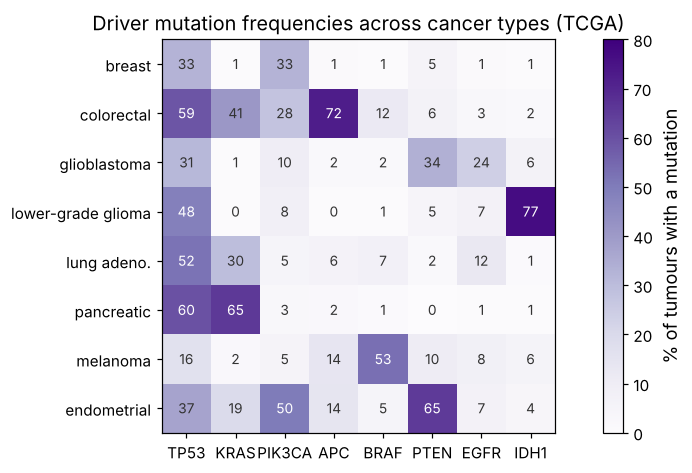

In [2]:
freq = muts.groupby(["study", "gene"])["sample"].nunique().unstack(fill_value=0)
freq = 100 * freq.div(pd.Series(n_samples), axis=0)
freq.index = [names[i.split("_")[0]] for i in freq.index]
genes = ["TP53", "KRAS", "PIK3CA", "APC", "BRAF", "PTEN", "EGFR", "IDH1"]
freq = freq[genes]
fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(freq.values, cmap="Purples", vmin=0, vmax=80)
ax.set_xticks(range(len(genes)), genes); ax.set_yticks(range(len(freq)), freq.index)
for i in range(freq.shape[0]):
    for j in range(freq.shape[1]):
        v = freq.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9, color="white" if v > 45 else "0.2")
plt.colorbar(im, ax=ax, label="% of tumours with a mutation"); ax.set_title("Driver mutation frequencies across cancer types (TCGA)")
save_fig("driver_heatmap"); plt.show()
R["kras_paad"] = f"{freq.loc['pancreatic', 'KRAS']:.0f}"; R["braf_skcm"] = f"{freq.loc['melanoma', 'BRAF']:.0f}"
R["idh_lgg"] = f"{freq.loc['lower-grade glioma', 'IDH1']:.0f}"; R["apc_crc"] = f"{freq.loc['colorectal', 'APC']:.0f}"
R["tp53_max"] = f"{freq['TP53'].max():.0f}"

![Figure P12-1. Percentage of tumours carrying a mutation in each gene, for eight cancer types from The Cancer Genome Atlas. Each cancer type has its own signature set of drivers; TP53 is common almost everywhere.](images/driver_heatmap.png)

Each cancer type has its own favourite drivers: *KRAS* in 65% of pancreatic cancers, *BRAF* in 53% of melanomas, *IDH1* in 77% of lower-grade gliomas, *APC* in 72% of colorectal cancers. *TP53* is mutated in many cancer types (up to 60% here). Endometrial cancer shows many genes mutated because some of these tumours have broken DNA repair and carry huge numbers of mutations.

Now the fingerprints. Where along each protein do the mutations fall?

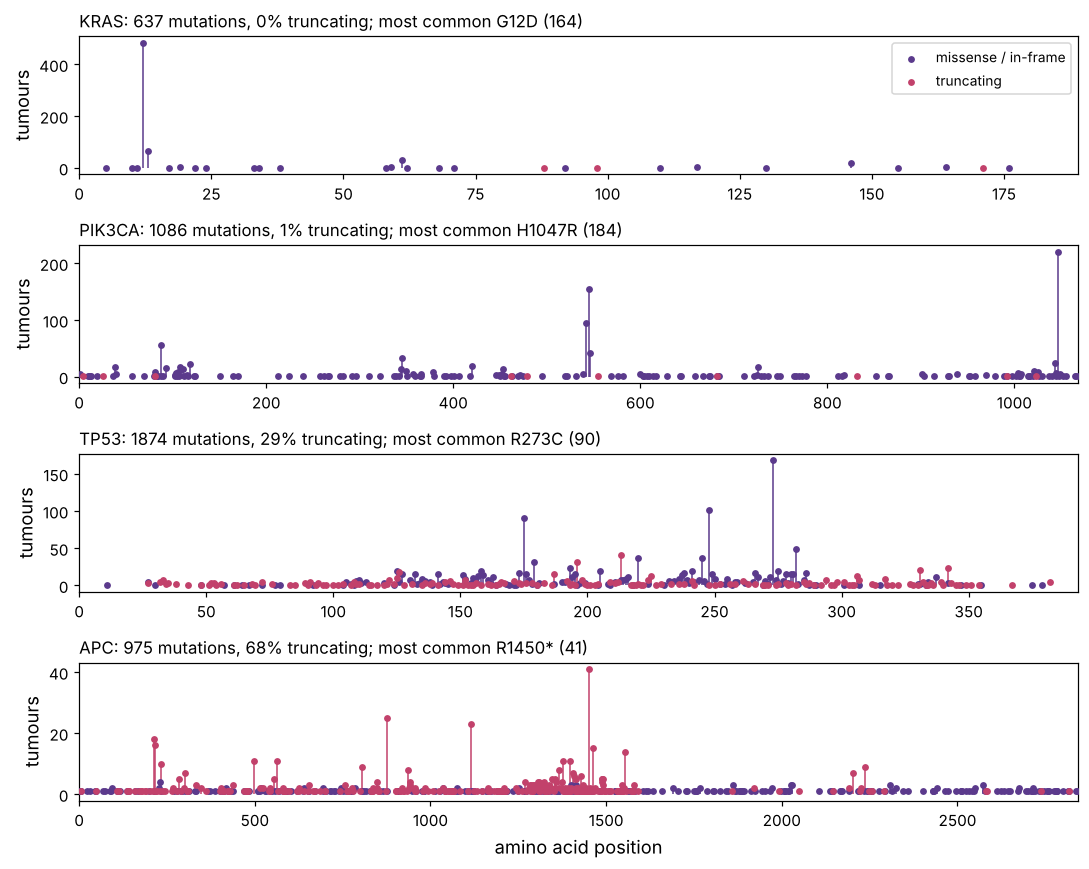

In [3]:
lengths = {"KRAS": 189, "PIK3CA": 1068, "TP53": 393, "APC": 2843}
truncating = {"Nonsense_Mutation", "Frame_Shift_Del", "Frame_Shift_Ins", "Splice_Site"}
fig, axs = plt.subplots(4, 1, figsize=(10, 8))
stats = {}
for ax, g in zip(axs, lengths):
    d = muts[(muts.gene == g) & muts.position.notna()]
    trunc = d.mutation_type.isin(truncating)
    for mask, c, lab in [(~trunc, "#5b3a8c", "missense / in-frame"), (trunc, "#c2416b", "truncating")]:
        counts = d[mask].position.astype(int).value_counts()
        ax.vlines(counts.index, 0, counts.values, color=c, lw=1)
        ax.scatter(counts.index, counts.values, color=c, s=12, label=lab, zorder=3)
    top = d.protein_change.value_counts()
    ax.set_xlim(0, lengths[g]); ax.set_ylabel("tumours")
    ax.set_title(f"{g}: {len(d)} mutations, {trunc.mean():.0%} truncating; most common {top.index[0]} ({top.iloc[0]})", fontsize=11, loc="left")
    stats[g] = (trunc.mean(), top.iloc[0] / len(d), top.index[0])
axs[0].legend(fontsize=9); axs[-1].set_xlabel("amino acid position")
save_fig("lollipops"); plt.show()
R["kras_top"] = f"{stats['KRAS'][1]:.0%}"; R["kras_top_name"] = stats["KRAS"][2]
R["apc_trunc"] = f"{stats['APC'][0]:.0%}"; R["kras_trunc"] = f"{stats['KRAS'][0]:.0%}"
R["tp53_trunc"] = f"{stats['TP53'][0]:.0%}"

![Figure P12-2. Positions of mutations along four proteins in TCGA tumours (taller = more tumours). The oncogenes KRAS and PIK3CA are hit at a few hotspots, almost always by missense changes. APC is hit all along its first half, mostly by truncating mutations. TP53 is a special case: mostly missense, concentrated in its DNA-binding domain.](images/lollipops.png)

The difference is striking. In *KRAS*, 26% of all mutations are a single change, G12D, and only 0% are truncating. In *APC*, 68% are truncating, scattered across the first half of the protein. *TP53* is mixed (29% truncating): it is a tumour suppressor, but its common missense mutations at arginines in the DNA-binding domain (R175, R248, R273) both destroy its function and interfere with the remaining normal copy. Bert Vogelstein and colleagues turned this pattern into a rule of thumb for classifying cancer genes (the "20/20 rule"), and chapter 20 builds a statistical driver-gene detector on the same idea.

### Mutual exclusivity

*KRAS* and *BRAF* sit one after the other in the same pathway (chapter P9). Once one is mutated, mutating the other adds little, so tumours rarely carry both. Let's test that in colorectal cancer:

In [4]:
from scipy.stats import fisher_exact
crc = muts[muts.study == "coadread_tcga_pan_can_atlas_2018"]
hot = crc[((crc.gene == "KRAS") & crc.protein_change.str.match(r"G1[23]|Q61", na=False)) |
          ((crc.gene == "BRAF") & (crc.protein_change == "V600E"))]
n_crc = n_samples["coadread_tcga_pan_can_atlas_2018"]
k = set(hot[hot.gene == "KRAS"]["sample"]); b = set(hot[hot.gene == "BRAF"]["sample"])
both, k_only, b_only = len(k & b), len(k - b), len(b - k)
neither = n_crc - both - k_only - b_only
table = [[both, b_only], [k_only, neither]]
odds, p = fisher_exact(table)
expected = len(k) * len(b) / n_crc
print(f"KRAS hotspot: {len(k)}, BRAF V600E: {len(b)}, both: {both} (expected if independent: {expected:.1f})")
print(f"Fisher's exact test: odds ratio {odds:.2f}, p = {p:.1e}")
R["both"] = both; R["exp_both"] = f"{expected:.0f}"; R["p_excl"] = f"{p:.0e}"

KRAS hotspot: 190, BRAF V600E: 48, both: 1 (expected if independent: 17.1)
Fisher's exact test: odds ratio 0.03, p = 1.2e-08


Under independence we would expect about 17 colorectal tumours with both a *KRAS* hotspot and *BRAF* V600E; there are 1 (p = 1e-08). **Mutual exclusivity** like this is used computationally to discover genes that act in the same pathway.

## Cancer develops in steps

In 1990 Eric Fearon and Bert Vogelstein described colorectal cancer as a sequence: loss of *APC* starts a benign polyp, an activating *KRAS* mutation makes it grow larger, and loss of *TP53* (and other changes) turns it into an invasive carcinoma. The idea that several hits are needed explains why cancer incidence climbs so steeply with age. If a cell needs $k$ rare, independent hits, the chance of having all of them by age $t$ grows roughly as $t^k$, so the yearly incidence grows as $t^{k-1}$ (Armitage and Doll, 1954).

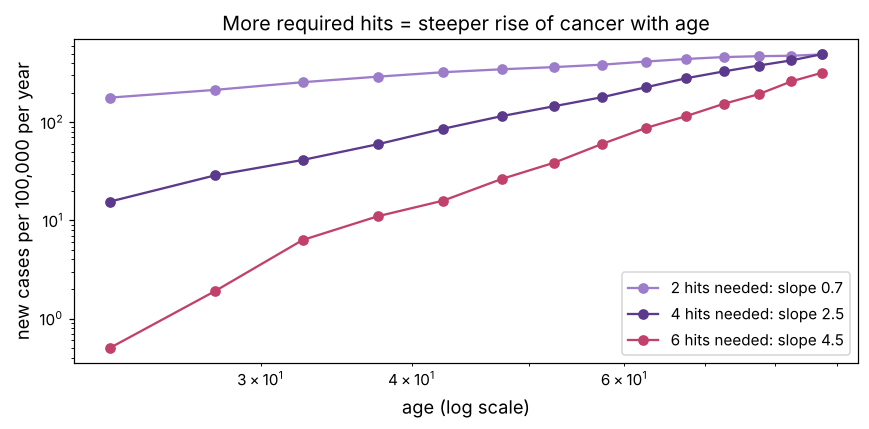

In [5]:
rng = np.random.default_rng(12)
def onset_ages(k, rate, n_people=200_000, max_age=100):
    """Each person's first cell to collect k hits; hits arrive as a Poisson process in each of many cell lineages."""
    # time to k-th hit in one lineage is Gamma(k, rate); the first of many lineages wins
    lineages = 50
    t = rng.gamma(k, 1 / rate, (n_people, lineages)).min(axis=1)
    return t[t < max_age]

fig, ax = plt.subplots(figsize=(8, 4))
for k, rate, c in [(2, 0.0013, "#9d7cc9"), (4, 0.0065, "#5b3a8c"), (6, 0.013, "#c2416b")]:
    ages = onset_ages(k, rate)
    hist, edges = np.histogram(ages, bins=np.arange(20, 91, 5))
    mid = (edges[:-1] + edges[1:]) / 2
    ok = hist > 0
    slope = np.polyfit(np.log(mid[ok]), np.log(hist[ok]), 1)[0]
    ax.loglog(mid[ok], hist[ok] / 200_000 * 1e5 / 5, "o-", color=c, label=f"{k} hits needed: slope {slope:.1f}")
ax.set_xlabel("age (log scale)"); ax.set_ylabel("new cases per 100,000 per year")
ax.set_title("More required hits = steeper rise of cancer with age"); ax.legend()
save_fig("age_incidence"); plt.show()

![Figure P12-3. Simulated cancer incidence against age, on log–log axes, when a cell must accumulate 2, 4 or 6 independent hits. The slope is a little below k − 1 (it flattens at older ages as the first cases use up the most susceptible people). Many real adult cancers rise with a slope of about 4–6.](images/age_incidence.png)

Real incidence curves for many adult carcinomas have log–log slopes of roughly 4–6, consistent with several rate-limiting steps. The model ignores the clonal expansions between hits, which in reality speed things up, as the first tab of the playground shows: each driver lets a clone grow, and a bigger clone is a bigger target for the next hit. Switch on an inherited first hit, as in familial adenomatous polyposis (an inherited *APC* mutation), and cancer arrives decades earlier.

::playground animations/cancer_lab.html 640

## The hallmarks of cancer

In 2000, and again in 2011 and 2022, Douglas Hanahan and Robert Weinberg organised the bewildering diversity of cancer into a short list of capabilities every cancer acquires. Click through them in the playground's second tab. In brief: **sustained growth signalling** (P9), **evading growth suppressors** and **resisting cell death** (P7), **unlimited replication** via telomerase (P7), **inducing blood vessels** (P1's diffusion limit), **invasion and metastasis**, **reprogrammed metabolism** (P9), and **avoiding immune destruction** (P10), enabled by **genome instability** and **tumour-promoting inflammation**, with **phenotypic plasticity** and **epigenetic reprogramming** (P6) among the latest additions. Each hallmark is also a family of drug targets.

## Where the mutations come from

| Source | Signature in the DNA | Example cancers |
|---|---|---|
| **Ageing**: spontaneous loss of methylated C (chapter P6) | C→T at CpG sites, accumulating like a clock | all tissues |
| **Tobacco smoke** | C→A changes | lung |
| **Ultraviolet light** | C→T at neighbouring pyrimidines (CC→TT) | skin melanoma |
| **APOBEC enzymes** (antiviral, chapter P3) | C→T and C→G in a TCW context | breast, bladder, cervix |
| **Defective mismatch repair** | huge numbers of small indels in repeats | some colorectal and endometrial |
| **Defective BRCA1/2 (homologous recombination)** | deletions with short matching sequences at the edges; many rearrangements | breast, ovarian, prostate |

Each process leaves a characteristic **mutational signature**, a pattern of which base changes in which neighbouring context. Separating a tumour's mutations into a mix of signatures is a matrix-factorisation problem that you'll solve with real data in chapter 20. About 5–10% of cancers involve a strong inherited risk, such as *BRCA1/2* (breast, ovarian), mismatch-repair genes (Lynch syndrome) or *TP53* (Li–Fraumeni syndrome).

## How cancer is treated

| Approach | How it works | Example |
|---|---|---|
| **Surgery** | remove the tumour; curative for many early cancers | |
| **Radiotherapy** | DNA damage kills dividing cells; hypoxic regions resist (chapter P1) | |
| **Chemotherapy** | poisons for dividing cells: DNA damage, blocked replication, frozen spindles (chapter P7) | cisplatin, 5-FU, paclitaxel |
| **Targeted therapy** | drugs against the specific driver | imatinib (BCR-ABL), osimertinib (EGFR), vemurafenib (BRAF V600E), sotorasib (KRAS G12C) |
| **Synthetic lethality** | exploit a weakness created by the tumour's own mutation | PARP inhibitors in *BRCA*-mutant cancers |
| **Hormone therapy** | block the hormone signals some cancers need | tamoxifen, enzalutamide |
| **Immunotherapy** | release or redirect the immune system (chapter P10) | pembrolizumab, CAR-T |

The landmark of targeted therapy is **imatinib**. Chronic myeloid leukaemia is driven by the **Philadelphia chromosome**, a swap between chromosomes 9 and 22 that fuses two genes into *BCR-ABL*, a permanently active kinase. Imatinib, approved in 2001, blocks that kinase, and turned a fatal leukaemia into a condition most patients live with for a normal lifespan. The drawback of all targeted therapies is **resistance**: tumours are diverse, evolving populations, and cells with a resistance mutation survive and regrow (chapter P7's playground, chapter 19). That is why combinations, sequencing of tumour DNA in the blood to catch resistance early, and evolution-informed dosing are major research areas.

:::idea
Cancer genomics changed oncology from organ-based to molecule-based. Lung cancers are now routinely sequenced, and the treatment depends on whether the tumour carries an *EGFR*, *ALK*, *KRAS* G12C, *BRAF* or another targetable change. Part 5 of this course works with exactly the kind of data you used in this chapter.
:::

## Summary

| Idea | One line |
|---|---|
| Malignant tumour | invades and can metastasise; most deaths are from metastasis |
| Oncogene | stuck accelerator; one copy; hotspot missense mutations |
| Tumour suppressor | broken brake; both copies; scattered truncating mutations |
| Multistep | several hits needed; incidence rises steeply with age |
| Mutual exclusivity | genes in the same pathway are rarely mutated together |
| Hallmarks | the capabilities every cancer acquires; each a drug-target family |
| Treatment | surgery, radiation, chemo, targeted, hormone, immunotherapy; resistance evolves |

:::check
1. Why are oncogene mutations concentrated at hotspots, but tumour-suppressor mutations spread out? *(Only specific changes activate a protein; almost any damaging change inactivates one.)*
2. Why do children with inherited retinoblastoma often get tumours in both eyes? *(Every cell already has one hit; only one more is needed.)*
3. *KRAS* and *BRAF* mutations are rarely found in the same colorectal tumour. Why? *(They act in the same pathway, so a second one adds little advantage.)*
4. What is synthetic lethality? Give an example. *(Losing either of two genes is tolerated, but losing both kills; PARP inhibitors kill BRCA-deficient cells.)*
5. Why does cancer incidence rise steeply with age? *(Several independent hits must accumulate in one cell lineage.)*
:::

:::exercise
Using the TCGA table, compare *PIK3CA* mutations in breast and endometrial cancer. (a) What are the three most common protein changes in each? (b) What fraction of endometrial tumours with any *PIK3CA* mutation also have a *PTEN* mutation, compared with what you'd expect if they were independent? Both genes act in the PI3K pathway. Does the result fit the mutual-exclusivity idea? Suggest a reason.
:::

<details><summary>Solution</summary>

In [6]:
for st in ["brca_tcga_pan_can_atlas_2018", "ucec_tcga_pan_can_atlas_2018"]:
    d = muts[(muts.study == st) & (muts.gene == "PIK3CA")]
    print(names[st.split("_")[0]], d.protein_change.value_counts().head(3).to_dict())
ucec = muts[muts.study == "ucec_tcga_pan_can_atlas_2018"]
p_set, t_set = set(ucec[ucec.gene == "PIK3CA"]["sample"]), set(ucec[ucec.gene == "PTEN"]["sample"])
n = n_samples["ucec_tcga_pan_can_atlas_2018"]
print(f"PIK3CA {len(p_set)}, PTEN {len(t_set)}, both {len(p_set & t_set)}, expected {len(p_set) * len(t_set) / n:.0f}")
print(fisher_exact([[len(p_set & t_set), len(p_set - t_set)], [len(t_set - p_set), n - len(p_set | t_set)]]))

breast {'H1047R': 129, 'E545K': 65, 'E542K': 43}
endometrial {'R88Q': 36, 'H1047R': 29, 'E542K': 17}
PIK3CA 259, PTEN 337, both 191, expected 169
SignificanceResult(statistic=np.float64(2.154713940370669), pvalue=np.float64(4.71933849971892e-05))


Breast cancer is dominated by H1047R (in the kinase domain) and E545K and E542K (in the helical domain). Endometrial cancer shares H1047R and E542K, but its single most common change is R88Q, in a different part of the protein: tissues can favour different ways of activating the same enzyme. In endometrial cancer, *PIK3CA* and *PTEN* mutations co-occur *more* often than expected, the opposite of mutual exclusivity, even though both act in the PI3K pathway. Two reasons are likely. Many endometrial tumours are hypermutated (broken mismatch repair or *POLE*), so they carry mutations in many genes at once and inflate every overlap. And partial pathway activation by each mutation may add up, so having both genuinely helps. Exclusivity is a useful clue, not a law, and real driver analysis must correct for each tumour's overall mutation burden (chapter 20).

</details>